# Addendum A: Shorter Embeddings in Part 2

**Candidate Name:** Matteo Antony Mistretta

**Date:** 2026-10-20

**Environment:** Python 3.14, scikit-learn 1.9, PyTorch 2.14 (CPU) (exact versions in `requirements.txt`).

*An extra experiment added after the submission: it tests a claim that Part 1C made and Part 2 never checked.*

## Overview

**The question.** Part 1C (Section 4) showed that the embeddings can be cut from 768 to 64 numbers without losing category information: the 10-nearest-neighbours vote stays at ~70%. It also suggested that a smaller input "could reduce overfitting in Part 2", since the network would have fewer weights to learn from ~2,400 training rows. Part 2 then kept the full 768 numbers without testing that idea. This addendum tests it.

**What "shorter" means.** The embedding model is *Matryoshka*-trained (README): its first *d* numbers form a smaller embedding that still works on its own. Shortening an embedding means keeping its first *d* numbers and rescaling the vector to length 1, which is what the API returns when asked for `truncation_dimension=d`. No new API calls are needed: the saved 768-number embeddings already contain every shorter version.

**The files involved:**

| File | Role |
|---|---|
| `benchmarks/part2_protocol.py` | Part 2's data, splits, network and training loop, copied from `part2.ipynb` (the network's input width now follows the data) |
| `benchmarks/matryoshka_part2.py` | This experiment; also runnable on its own: `python benchmarks/matryoshka_part2.py` |

**Plan:** retrain Part 2's final model on embeddings of 768, 512, 256, 128 and 64 numbers, with exactly the protocol of Part 2's robustness check (Section 10): the same 5 grouped splits (seeds 0-4), anchors + positives for training, early stopping on validation, scores on the untouched test sets. The 768 row must reproduce Part 2's numbers, which checks that the copied code behaves the same.

### Setup

**What:** import the libraries and the experiment's functions, and check that a shortened embedding has length 1.

In [1]:
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sys.path.insert(0, str(Path.cwd()))                  # the project root, to import from benchmarks/
sns.set_theme(style="whitegrid", context="notebook")
FIG_DIR = Path("figures"); FIG_DIR.mkdir(exist_ok=True)
pd.set_option("display.max_colwidth", 70)
from benchmarks.matryoshka_part2 import run_experiment, summarize, truncate
from benchmarks.part2_protocol import X_anchor

for d in [768, 64]:
    lengths = np.linalg.norm(truncate(X_anchor, d), axis=1)
    print(f"{d:3d} numbers: vector lengths between {lengths.min():.4f} and {lengths.max():.4f}")

768 numbers: vector lengths between 1.0000 and 1.0000
 64 numbers: vector lengths between 1.0000 and 1.0000


## 1. Results

**What:** train and test the network once per (embedding size, split): 5 sizes × 5 splits = 25 trainings, about a minute on CPU. For reference, kNN (k = 10) is scored on the same shortened embeddings.

**How to read the table:** one row per embedding size; scores are averages over the 5 test sets, and `_std` is their standard deviation, the seed-to-seed spread. Differences smaller than that spread are noise. `nn_weights` is the number of weights the network has to learn.

In [2]:
t0 = time.perf_counter()
res = run_experiment()
print(f"Time: {time.perf_counter() - t0:.0f} s")
summary = summarize(res)
summary.round(3)

Time: 64 s


,nn_acc,nn_acc_std,nn_f1,nn_f1_std,knn_acc,knn_f1,nn_weights
dim,,,,,,,
768,0.739,0.023,0.716,0.030,0.685,0.672,461833
512,0.728,0.020,0.704,0.030,0.680,0.665,330761
256,0.728,0.027,0.701,0.037,0.680,0.663,199689
128,0.723,0.013,0.702,0.024,0.682,0.665,134153
64,0.719,0.016,0.697,0.025,0.680,0.664,101385


**What:** the same results as a chart: test accuracy against embedding size, with the seed-to-seed spread as error bars. The horizontal axis is logarithmic (each step halves the size, roughly), and the left end is the smallest embedding.

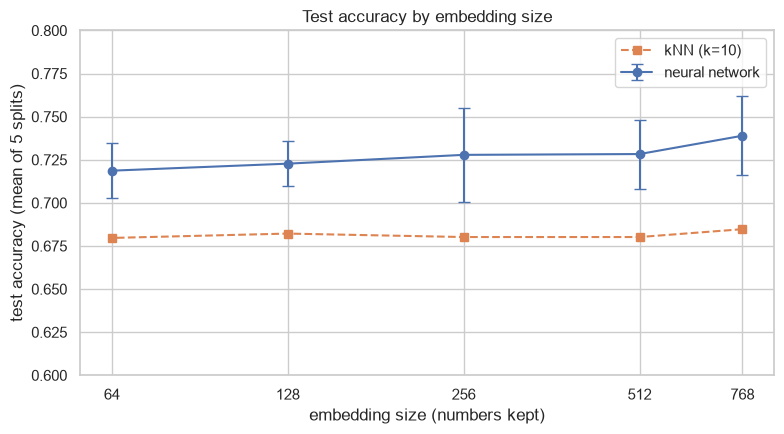

In [3]:
fig, ax = plt.subplots(figsize=(8, 4.5))
dims = summary.index.to_numpy()
ax.errorbar(dims, summary["nn_acc"], yerr=summary["nn_acc_std"], marker="o", capsize=4, label="neural network")
ax.plot(dims, summary["knn_acc"], marker="s", ls="--", label="kNN (k=10)")
ax.set_xscale("log", base=2); ax.set_xticks(dims, [str(d) for d in dims])
ax.set(xlabel="embedding size (numbers kept)", ylabel="test accuracy (mean of 5 splits)", ylim=(0.6, 0.8),
       title="Test accuracy by embedding size")
ax.legend()
plt.tight_layout(); plt.savefig(FIG_DIR / "addendum_a_matryoshka.png", dpi=120); plt.show()

**Observations - shorter embeddings**
- **The copied code behaves like Part 2's**: with 768 numbers it reproduces Part 2's result exactly, **73.9% ± 2.3 accuracy and 0.716 macro-F1**, and kNN's 68.5% (table above).
- **Shorter embeddings never help the network.** Accuracy goes down step by step, from 73.9% (768) to 72.8% (512 and 256), 72.3% (128) and **71.9% (64)**, and macro-F1 from 0.716 to 0.697. Each single step is smaller than the seed-to-seed spread (1.3-2.7 points), so no single step is significant, but the direction is the same at every size and no size beats 768.
- **The overfitting idea from Part 1C is not supported.** Shortening the input shrinks only the first layer: at 64 numbers the network still has **101,385 weights, 4.6x fewer, not 12x**, because the 512 → 128 layer stays the same. And Part 2 (Section 6) had already found that a smaller network is no better: the number of weights is not what limits this model.
- **kNN barely moves** (68.5% → 68.0%), confirming Part 1C's Matryoshka check. The network, however, uses some information in the later numbers that a neighbour vote does not, which is why it loses ~2 points where kNN loses ~0.5.

## Addendum A Summary
- Retraining Part 2's final model on embeddings shortened to 512, 256, 128 and 64 numbers gives **slightly lower** test accuracy at every size (71.9% at 64 versus 73.9% at 768), never higher. Keeping the full 768 numbers in Part 2 was the right choice, now backed by a measurement instead of a default.
- Part 1C's "no measurable loss at 64 numbers" holds for the neighbour vote it measured, not for the network, which loses ~2 points. For storage- or speed-sensitive production use, 64 numbers remain a reasonable trade: 12x less storage for ~2 points of accuracy.